In [ ]:
!pip install gym-pusht

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.4/77.4 MB 50.3 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 30.7 MB/s  0:00:00
  Attempting uninstall: opencv-python
    Found existing installation: opencv-python 5.0.0.93
    Uninstalling opencv-python-5.0.0.93:
      Successfully uninstalled opencv-python-5.0.0.93
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [gym-pusht]


In [ ]:
# !pip install torch torch_tpu

In [ ]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.lines import Line2D
import numpy as np
from pathlib import Path
import torch
import time

In [ ]:
print(matplotlib.get_backend(), flush=True)
fig, ax = plt.subplots()
print("subplots succeeded", flush=True)
plt.close(fig)

Agg
subplots succeeded


In [ ]:
# example.py
import gymnasium as gym
import gym_pusht
from gymnasium.wrappers import FrameStackObservation
from gymnasium.wrappers import FlattenObservation
from gymnasium.wrappers import GrayscaleObservation

import cv2
import copy
import torch
import torch.nn as nn
from torch.distributions import Normal

# env = gym.make("gym_pusht/PushT-v0",
#                render_mode='rgb_array',
#                obs_type="state")
# observation, info = env.reset()

# for _ in range(10):
#     action = env.action_space.sample()
#     observation, reward, terminated, truncated, info = env.step(action)
#     image = env.render()

#     if terminated or truncated:
#         observation, info = env.reset()

# env.close()

In [ ]:
# @title
from gymnasium import ActionWrapper, spaces

### Wrap pushT environment to use a velocity-based action space (instead of position)
class PushTVelocityWrapper(ActionWrapper):
    def __init__(self, env, max_speed=40.0, min_speed=5.0):
        super().__init__(env)

        self.max_speed = max_speed
        self.min_speed = min_speed
        self.action_space = spaces.Box(
            low=-1.0,
            high=1.0,
            shape=env.action_space.shape,
            dtype=np.float32,
        )

    def action(self, normalized_velocity):
        current_position = np.asarray(self.unwrapped.agent.position, dtype=np.float32)
        # print(f'current position {current_position}')

        velocity = np.clip(normalized_velocity, -1.0, 1.0) * self.max_speed
        speed = np.linalg.norm(velocity)
        # print(f'velocity {velocity}')

        # Floor nonzero commands; leave a zero command as a stop.
        if 1e-6 < speed < self.min_speed:
            velocity *= self.min_speed / speed
        # print(f'{self.unwrapped.control_hz}')
        target_position = current_position + velocity / self.unwrapped.control_hz

        low = self.env.action_space.low
        high = self.env.action_space.high
        # print(f'{np.clip(target_position, low, high)}')
        return np.clip(target_position, low, high).astype(np.float32)

In [ ]:
class NormalizeObservation(gym.ObservationWrapper):
    def __init__(self, env):
        super().__init__(env)
        self.observation_space = gym.spaces.Box(
            low=-1.0,
            high=1.0,
            shape=(5,),
            dtype=np.float32
        )

    def observation(self, obs):
        obs = np.asarray(obs, dtype=np.float32).copy()

        # Assuming the observation is:
        # [pusher_x, pusher_y, block_x, block_y, block_angle]

        obs[:4] = (obs[:4] / 256.0) - 1.0
        obs[4] = obs[4] / np.pi

        # Represent angle as sin/cos instead of raw angle
        # angle = obs[4]
        # obs[4] = np.sin(angle)
        # (For a 2D sin/cos representation, you'd expand the observation.)

        return obs

In [ ]:
# @title
class DistanceCurriculumAndRewardWrapper(gym.Wrapper):
    def __init__(
        self,
        env,#: gym.Env,
        max_distance=30,
        max_angle=np.deg2rad(15),
        max_attempts=20_000, # Kept for signature compatibility, but unused for RNG reset now
        agent_object_weight=0.1,
        object_goal_weight=1.0,
        object_goal_angle_weight=1.0,
        contact_bonus=0.1,
        distance_scale=512.0,
    ):
        super().__init__(env)
        self.agent_object_weight = agent_object_weight
        self.object_goal_weight = object_goal_weight
        self.object_goal_angle_weight = object_goal_angle_weight
        self.contact_bonus = contact_bonus
        self.distance_scale = distance_scale
        self.max_distance = max_distance
        self.max_angle = max_angle

    def _metrics(self, info):
        agent_xy = np.asarray(info["pos_agent"][:2])
        object_xy = np.asarray(info["block_pose"][:2])
        goal_xy = np.asarray(info["goal_pose"][:2])
        angle_delta = info["block_pose"][2] - info["goal_pose"][2]
        # normalize angle delta to -pi, pi
        angle_difference = float(np.arctan2(np.sin(angle_delta), np.cos(angle_delta)))

        # Check the pusher's shape against the block's shapes.
        base = self.unwrapped
        contact = any(
            hit.shape.body is base.block
            for agent_shape in base.agent.shapes
            for hit in base.space.shape_query(agent_shape)
        )

        return {
            "agent_object_distance": float(np.linalg.norm(agent_xy - object_xy)),
            "object_goal_distance": float(np.linalg.norm(object_xy - goal_xy)),
            "object_goal_angle_difference": angle_difference,
            "object_goal_angle_error": abs(angle_difference),
            "contact": bool(contact),
        }

    def reset(self, *, seed=None, options=None):
        # Reset the base environment normally
        original_obs, info = self.env.reset(seed=seed, options=options)
        base = self.env.unwrapped

        if options is not None and "reset_to_state" in options:
            # The base env handled the reset state, just grab the updated obs/info
            obs = original_obs
            info = dict(info)
            info["pos_agent"] = np.array(base.agent.position, dtype=np.float32)
            info["block_pose"] = np.array([base.block.position.x, base.block.position.y, base.block.angle], dtype=np.float32)
        else:
            # Generate a random distance and angle within the current curriculum limits
            distance = base.np_random.uniform(0, self.max_distance)
            angle_error = base.np_random.uniform(0, self.max_angle)

            # Randomly choose direction for angle
            if base.np_random.uniform(0, 1) < 0.5:
                angle_error *= -1

            # Randomly choose a direction vector for the distance offset
            theta = base.np_random.uniform(0, 2 * np.pi)
            offset_x = distance * np.cos(theta)
            offset_y = distance * np.sin(theta)

            # Calculate new block pose based on goal pose (with generous padding for walls)
            goal_x, goal_y, goal_angle = base.goal_pose
            new_block_x = np.clip(goal_x + offset_x, 80, 432)
            new_block_y = np.clip(goal_y + offset_y, 80, 432)
            new_block_angle = goal_angle + angle_error

            # Prevent physics explosion: move agent if it overlaps with the new block position
            for _ in range(100):
                agent_x, agent_y = base.agent.position
                if np.hypot(new_block_x - agent_x, new_block_y - agent_y) > 100:
                    break
                base.agent.position = (
                    base.np_random.uniform(80, 432),
                    base.np_random.uniform(80, 432)
                )

            # Override the block's physical state in the environment
            print(f'before: {base.block.position}')
            base.block.position = (new_block_x, new_block_y)
            print(f'after: {base.block.position}')
            base.block.angle = new_block_angle

            # Reset block AND agent velocities just in case to prevent immediate collisions
            base.block.velocity = (0, 0)
            base.block.angular_velocity = 0
            base.agent.velocity = (0, 0)
            base.agent.angular_velocity = 0

            # Step the physics engine once to update internal states (like shapes)
            base.space.step(1.0 / base.control_hz)

            info = dict(info)
            # Manually update the info dictionary
            info["pos_agent"] = np.array(base.agent.position, dtype=np.float32)
            info["block_pose"] = np.array([new_block_x, new_block_y, new_block_angle], dtype=np.float32)

            # Dynamically set the observation based on original obs type
            if isinstance(original_obs, np.ndarray) and original_obs.ndim == 1:
                # Manually update the state observation array: [agent_x, agent_y, block_x, block_y, block_angle]
                obs = np.array([
                    info["pos_agent"][0], info["pos_agent"][1],
                    new_block_x, new_block_y, new_block_angle
                ], dtype=np.float32)
            else:
                # For pixel observations, render the environment to capture the updated state
                obs = self.env.render()
                # The wrapper expects 96x96 images, but render() usually outputs 512x512.
                # We resize it back to the original observation shape.
                if obs.shape != original_obs.shape:
                    obs = cv2.resize(obs, (original_obs.shape[1], original_obs.shape[0]))

        # Calculate initial distances for metrics
        print(f'final: {base.block.position}')
        block_xy = np.asarray(base.block.position)
        goal_xy = np.asarray(base.goal_pose[:2])
        actual_distance = np.linalg.norm(block_xy - goal_xy)

        block_angle = base.block.angle
        goal_angle = base.goal_pose[2]
        actual_angle_error = abs(np.arctan2(np.sin(block_angle - goal_angle), np.cos(block_angle - goal_angle)))

        info["initial_goal_distance"] = float(actual_distance)
        info["initial_angle_error"] = float(actual_angle_error)
        metrics = self._metrics(info)
        self._previous = metrics
        self._was_contact = metrics["contact"]

        return obs, {**info, **metrics}

    def step(self, action):
        observation, base_reward, terminated, truncated, info = self.env.step(action)

        # Override info["pos_agent"] with the true physical position from pymunk
        # because the default tracks the commanded target (red crosshair).
        info["pos_agent"] = np.array(self.unwrapped.agent.position, dtype=np.float32)

        metrics = self._metrics(info)

        # to incentivize contact initially in learning, reward based off distance to object
        dist_reward = (1.0 - metrics["agent_object_distance"] / self.distance_scale)

        # INVERTED: closer distance to goal gives higher reward (1.0 is right on the goal)
        block_goal_dist = 1.0 - (metrics["object_goal_distance"] / self.distance_scale)

        # INVERTED: lower angle error gives higher reward (1.0 is perfectly aligned)
        angle_reward = 1.0 - (metrics["object_goal_angle_error"] / np.pi)

        # negative reward for going near bounds
        bound_reward = 0

        # adjust termination condition and bonus reward
        episode_end_reward = 0
        if metrics["object_goal_distance"] < 15.0/512.0 and metrics["object_goal_angle_error"] < (np.pi/18)/np.pi:
            # within 15 pixels and 10 degrees
            terminated = True
            episode_end_reward = 500  # Massive bonus to encourage finishing the task

        # Give a one-time bonus when contact is first made.
        contact_reward = self.contact_bonus * float(
            metrics["contact"] and not self._was_contact
        )

        step_penalty = -4.0  # Increased penalty to offset dense reward milking

        reward = 0.01*dist_reward + block_goal_dist*0.3 + angle_reward*0.05 + episode_end_reward*0.1 + step_penalty*0.1 + bound_reward

        info = {
            **info,
            **metrics,
            "dist_reward": float(dist_reward),
            "block_goal_dist": float(block_goal_dist),
            "angle_reward": float(angle_reward),
            "episode_end_reward": float(episode_end_reward),
            "step_penalty": float(step_penalty),
            "contact_reward": float(contact_reward),
        }

        self._previous = metrics
        self._was_contact = metrics["contact"]
        return observation, reward, terminated, truncated, info


In [ ]:
class ActionSmoothnessPenaltyWrapper(gym.Wrapper):
    """Penalizes large changes in action to encourage smooth continuous behavior."""
    def __init__(self, env, penalty_weight=0.1):
        super().__init__(env)
        self.penalty_weight = penalty_weight
        self.last_action = None

    def reset(self, **kwargs):
        self.last_action = np.zeros(self.action_space.shape, dtype=np.float32)
        return self.env.reset(**kwargs)

    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)

        # Penalize the difference between the current action and the previous action
        if self.last_action is not None:
            jitter_penalty = -self.penalty_weight * np.linalg.norm(action - self.last_action)
        else:
            jitter_penalty = 0.0

        self.last_action = action.copy()

        # Add penalty to the reward
        reward += jitter_penalty
        info['jitter_penalty'] = float(jitter_penalty)

        return obs, reward, terminated, truncated, info


In [ ]:
"""Parameters"""
class params():
    """PPO parameters"""
    policy_type: str = "mlp"
    state_dim: int = 5 # 5 base state features * 4 stacked frames
    action_dim: int = 2
    action_std: float = 0.3
    action_std_decay_rate: float = 1
    min_action_std: float = 0.05

    lr_actor: float = 0.0001
    lr_critic: float = 0.0003
    max_ppo_steps: int = 300
    max_episode_len: int = 400
    clip: float = 0.2
    discount_gamma: float = 0.99
    gae_lambda: float = 0.95
    update_epochs: int = 7
    batch_size: int = 32
    entropy_coefficient: float = 0.01

    initial_max_dist: float = 30 # Reduced from 90 to make initial learning possible
    initial_max_angle = 25 # Reduced from 120 degrees
    max_speed = 130 # maximum speed of pusher arm
    min_speed = 25
    action_every_n_steps = 4
    frame_stack_size = 8

hp = params()


In [ ]:
env = DistanceCurriculumAndRewardWrapper(
    gym.make("gym_pusht/PushT-v0",
             render_mode="rgb_array",
             obs_type="state"),
    max_distance=hp.initial_max_dist,
    max_angle=np.deg2rad(hp.initial_max_angle),
)

env = PushTVelocityWrapper(env, max_speed=hp.max_speed, min_speed=hp.min_speed)
env = ActionSmoothnessPenaltyWrapper(env, penalty_weight=0.5) # Apply jitter penalty
env = NormalizeObservation(env)
env = FrameStackObservation(env, stack_size=hp.frame_stack_size)
env = FlattenObservation(env)

print(f'{env.observation_space} | shape: {env.observation_space.shape[0]}')
print(f'{env.action_space} | shape: {env.action_space.shape[0]}')

obs, info = env.reset()
next_observation, reward, terminated, truncated, info = env.step(np.array([1.0, 0]))
# print(f'info {info}')
# print(f'object_goal_distance: {info["object_goal_distance"]}')
# print("Distance:", info["initial_goal_distance"])
# print("Angle error (degrees):", np.rad2deg(info["initial_angle_error"]))

# Increase difficulty between episodes:
# env.set_limits(max_distance=60, max_angle=np.deg2rad(30))


Box(-1.0, 1.0, (40,), float32) | shape: 40
Box(-1.0, 1.0, (2,), float32) | shape: 2
before: Vec2d(357.72233959805374, 271.7873131340444)
after: Vec2d(228.42395755270104, 264.037738773596)
final: Vec2d(220.75237158970805, 191.02333979155807)


In [ ]:
print([attr for attr in dir(env.unwrapped) if 'agent' in attr or 'body' in attr or 'control' in attr])

['agent', 'control_hz', 'get_goal_pose_body', 'teleop_agent']


In [ ]:
print('Agent:', type(env.unwrapped.agent))
print('Teleop Agent:', type(env.unwrapped.teleop_agent))
print('Agent position:', env.unwrapped.agent.position)
print('Teleop Agent position:', env.unwrapped.teleop_agent.position)

Agent: <class 'pymunk.body.Body'>
Teleop Agent: <class 'method'>
Agent position: Vec2d(289.8437332168747, 76.0)


AttributeError: 'function' object has no attribute 'position'

In [ ]:
print('Physical bodies in space:')
for body in env.unwrapped.space.bodies:
    print(f'- Body type: {body.body_type}, position: {body.position}')

Physical bodies in space:
- Body type: 1, position: Vec2d(289.8437332168747, 76.0)
- Body type: 0, position: Vec2d(314.2028560922011, 221.13102903336102)


In [ ]:
import inspect
print(inspect.getsource(env.unwrapped.reset))

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self._setup()

        if options is not None and options.get("reset_to_state") is not None:
            state = np.array(options.get("reset_to_state"))
        else:
            # we use the env's RNG instead of global np.random
            state = np.array(
                [
                    self.np_random.integers(50, 450),
                    self.np_random.integers(50, 450),
                    self.np_random.integers(100, 400),
                    self.np_random.integers(100, 400),
                    self.np_random.uniform(-np.pi, np.pi),
                ]
            )
        self._set_state(state)

        observation = self.get_obs()
        info = self._get_info()
        info["is_success"] = False

        if self.render_mode == "human":
            self.render()

        return observation, info



In [ ]:
# @title
### Test policy and save results as gifs

# record 10 random rollouts
observation, info = env.reset()
frames = []
episode_steps = 0
start_time = time.perf_counter()

max_len = 100
while episode_steps < max_len:
    state = torch.as_tensor(observation, dtype=torch.float32).unsqueeze(0)
    if episode_steps < 20:
        action = np.array([0, 0])
    elif episode_steps < 40:
        action = np.array([2.0, 0])
    else:
        action = np.array([0, -0.1])
    # action = model.policy.act(state)
    # with torch.inference_mode():
    #     action, _, _ = model.policy_old.act(state)
    #     environment_action = model._to_environment_action(action)
    print(f'info: {info}')

    steps_to_run = min(
        4,
        max_len - episode_steps,
    )
    for _ in range(steps_to_run):
        observation, reward, terminated, truncated, info = env.step(action)
        episode_steps += 1
        frames.append(env.render())
        if terminated or truncated:
            break

    if terminated or truncated:
        break

save_frames_as_gif(frames, f'rollout.gif', fps=10, frame_stride=2, max_size=(256, 256))

info: {'pos_agent': array([372.7284 , 144.45073], dtype=float32), 'vel_agent': array([0., 0.]), 'block_pose': array([266.0049   , 249.41022  ,  -2.1585793], dtype=float32), 'goal_pose': array([256.        , 256.        ,   0.78539816]), 'n_contacts': 0, 'is_success': False, 'initial_goal_distance': 77.79206577892647, 'initial_angle_error': 2.9439775052772026, 'agent_object_distance': 149.68765258789062, 'object_goal_distance': 11.980130507270296, 'object_goal_angle_difference': -2.9439775129152705, 'object_goal_angle_error': 2.9439775129152705, 'contact': False}
current position [372.7284  144.45073]
current position [372.7284  144.45073]
current position [372.7284  144.45073]
current position [372.7284  144.45073]
info: {'pos_agent': array([372.7284 , 144.45073], dtype=float32), 'vel_agent': array([-1.06634699e-05, -1.83560863e-06]), 'block_pose': array([187.74682421, 293.32438202,  -2.15857934]), 'goal_pose': array([256.        , 256.        ,   0.78539816]), 'n_contacts': 0, 'is_suc

/tmp/ipykernel_3517/1720998560.py:19: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(np.ascontiguousarray(frame[:, :, :3]), mode="RGB")


In [ ]:
#### Convolutional network environment init
env = DistanceCurriculumAndRewardWrapper(
    gym.make("gym_pusht/PushT-v0",
             render_mode="rgb_array",
             obs_type="pixels"),
    max_distance=hp.initial_max_dist,
    max_angle=np.deg2rad(hp.initial_max_angle),
)

env = PushTVelocityWrapper(env, max_speed=hp.max_speed, min_speed=hp.min_speed)
env = GrayscaleObservation(env)
env = FrameStackObservation(env, stack_size=hp.frame_stack_size)

print(f'{env.observation_space} | shape: {env.observation_space.shape}')
print(f'{env.action_space} | shape: {env.action_space.shape[0]}')

obs, info = env.reset()
print("Distance:", info["initial_goal_distance"])
print("Angle error (degrees):", np.rad2deg(info["initial_angle_error"]))

Box(0, 255, (8, 96, 96), uint8) | shape: (8, 96, 96)
Box(-1.0, 1.0, (2,), float32) | shape: 2
Distance: 107.99164349029374
Angle error (degrees): 33.44758512433936


In [ ]:
# @title
############# print all hyperparameters #############

print("--------------------------------------------------------------------------------------------")

print("max training timesteps : ", hp.max_ppo_steps)
print("max timesteps per episode : ", hp.max_episode_len)

# print("model saving frequency : " + str(save_model_freq) + " timesteps")
# print("log frequency : " + str(log_freq) + " timesteps")
# print("printing average reward over episodes in last : " + str(print_freq) + " timesteps")

print("--------------------------------------------------------------------------------------------")

print("state space dimension : ", hp.state_dim)
print("action space dimension : ", hp.action_dim)

print("--------------------------------------------------------------------------------------------")

print("Initializing a continuous action space policy")
print("--------------------------------------------------------------------------------------------")
print("starting std of action distribution : ", hp.action_std)
print("decay rate of std of action distribution : ", hp.action_std_decay_rate)
print("minimum std of action distribution : ", hp.min_action_std)
# print("decay frequency of std of action distribution : " + str(action_std_decay_freq) + " timesteps")

print("--------------------------------------------------------------------------------------------")

# print("PPO update frequency : " + str() + " timesteps")
print("PPO K epochs : ", hp.update_epochs)
print("PPO epsilon clip : ", hp.clip)
print("discount factor (gamma) : ", hp.discount_gamma)

print("--------------------------------------------------------------------------------------------")

print("optimizer learning rate actor : ", hp.lr_actor)
print("optimizer learning rate critic : ", hp.lr_critic)

--------------------------------------------------------------------------------------------
max training timesteps :  300
max timesteps per episode :  400
--------------------------------------------------------------------------------------------
state space dimension :  5
action space dimension :  2
--------------------------------------------------------------------------------------------
Initializing a continuous action space policy
--------------------------------------------------------------------------------------------
starting std of action distribution :  0.3
decay rate of std of action distribution :  1
minimum std of action distribution :  0.05
--------------------------------------------------------------------------------------------
PPO K epochs :  7
PPO epsilon clip :  0.2
discount factor (gamma) :  0.99
--------------------------------------------------------------------------------------------
optimizer learning rate actor :  0.0001
optimizer learning rate critic :

In [ ]:
# @title
class ActorCritic(nn.Module):
    def __init__(self, state_dim: int, action_dim: int, action_std: float = 0.5):
        super().__init__()
        self.actor = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 128),
            nn.Tanh(),
            nn.Linear(128, 64),
            nn.Tanh(),
            nn.Linear(64, action_dim),
            nn.Tanh(),
        )
        self.critic = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 128),
            nn.Tanh(),
            nn.Linear(128, 64),
            nn.Tanh(),
            nn.Linear(64, 1),
        )
        self.log_std = nn.Parameter(torch.full((action_dim,), np.log(action_std)))

    def get_distribution(self, state: torch.Tensor) -> Normal:
        mean = self.actor(state)
        std = self.log_std.exp().expand_as(mean)
        return Normal(mean, std)

    def act(self, state: torch.Tensor):
        dist = self.get_distribution(state)
        action = dist.sample()
        return action, dist.log_prob(action).sum(dim=-1), self.critic(state).squeeze(-1)

    def evaluate(self, state: torch.Tensor, action: torch.Tensor):
        dist = self.get_distribution(state)
        log_prob = dist.log_prob(action).sum(dim=-1)
        entropy = dist.entropy().sum(dim=-1)
        value = self.critic(state).squeeze(-1)
        return log_prob, value, entropy

In [ ]:
class ActorCriticWithHistory(nn.Module):
    def __init__(self, state_dim: int, action_dim: int, history_len: int=8, action_std: float = 0.3):
        super().__init__()
        self.actor = nn.Sequential(
            nn.Linear(state_dim, 100),
            nn.Tanh(),
            nn.Linear(100, 128),
            nn.Tanh(),
            nn.Linear(128, 64),
            nn.Tanh(),
            nn.Linear(64, action_dim),
        )
        self.critic = nn.Sequential(
            nn.Linear(state_dim, 100),
            nn.Tanh(),
            nn.Linear(100, 128),
            nn.Tanh(),
            nn.Linear(128, 64),
            nn.Tanh(),
            nn.Linear(64, 1),
        )
        self.log_std = nn.Parameter(torch.full((action_dim,), np.log(action_std)))

    def get_distribution(self, state: torch.Tensor) -> Normal:
        mean = self.actor(state)
        std = self.log_std.exp().expand_as(mean)
        return Normal(mean, std)

    def act(self, state: torch.Tensor):
        dist = self.get_distribution(state)
        action = dist.sample()
        return action, dist.log_prob(action).sum(dim=-1), self.critic(state).squeeze(-1)

    def evaluate(self, state: torch.Tensor, action: torch.Tensor):
        dist = self.get_distribution(state)
        log_prob = dist.log_prob(action).sum(dim=-1)
        entropy = dist.entropy().sum(dim=-1)
        value = self.critic(state).squeeze(-1)
        return log_prob, value, entropy

In [ ]:
class ActorCriticDiscreteWithHistory(nn.Module):
    def __init__(self, state_dim: int, action_dim: int, history_len: int=8, num_bins: int=11):
        super().__init__()
        self.num_bins = num_bins
        self.action_dim = action_dim
        self.actor = nn.Sequential(
            nn.Linear(state_dim, 100),
            nn.Tanh(),
            nn.Linear(100, 128),
            nn.Tanh(),
            nn.Linear(128, 64),
            nn.Tanh(),
            nn.Linear(64, action_dim * num_bins),
        )
        self.critic = nn.Sequential(
            nn.Linear(state_dim, 100),
            nn.Tanh(),
            nn.Linear(100, 128),
            nn.Tanh(),
            nn.Linear(128, 64),
            nn.Tanh(),
            nn.Linear(64, 1),
        )

    def get_distribution(self, state: torch.Tensor):
        logits = self.actor(state)
        # Split logits into action_dim parts
        logits_split = torch.split(logits, self.num_bins, dim=-1)
        dists = [torch.distributions.Categorical(logits=l) for l in logits_split]
        return dists

    def act(self, state: torch.Tensor):
        dists = self.get_distribution(state)
        actions = [dist.sample() for dist in dists]
        log_probs = [dist.log_prob(a) for dist, a in zip(dists, actions)]

        action = torch.stack(actions, dim=-1)
        log_prob = torch.stack(log_probs, dim=-1).sum(dim=-1)
        return action, log_prob, self.critic(state).squeeze(-1)

    def evaluate(self, state: torch.Tensor, action: torch.Tensor):
        dists = self.get_distribution(state)
        log_probs = []
        entropies = []
        for i, dist in enumerate(dists):
            log_probs.append(dist.log_prob(action[..., i]))
            entropies.append(dist.entropy())

        log_prob = torch.stack(log_probs, dim=-1).sum(dim=-1)
        entropy = torch.stack(entropies, dim=-1).sum(dim=-1)
        value = self.critic(state).squeeze(-1)
        return log_prob, value, entropy

### Actor CNN

In [ ]:
# @title
class ActorCriticCNN(nn.Module):
    def __init__(self, in_channels: int = 4, action_dim: int = 2, action_std: float = 0.4):
        super().__init__()

        # Shared feature extractor for spatial processing of 96x96 frames
        self.feature_extractor = nn.Sequential(
            nn.Conv2d(in_channels=in_channels, out_channels=32, kernel_size=8, stride=4),
            nn.ReLU(),
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=4, stride=2),
            nn.ReLU(),
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, stride=1),
            nn.ReLU(),
            nn.Flatten()
        )

        # Compute flattened feature dimension dynamically for a 96x96 input image
        # Shape progression: 96x96 -> (with 8x8 s=4) 23x23 -> (with 4x4 s=2) 10x10 -> (with 3x3 s=1) 8x8
        # Flat features: 64 * 8 * 8 = 4096
        flat_features_dim = 4096

        # Policy Head (Actor)
        self.actor = nn.Sequential(
            nn.Linear(flat_features_dim, 256),
            nn.ReLU(),
            nn.Linear(256, action_dim),
            nn.Tanh() # Continuous actions bound between [-1, 1]
        )

        # Value Head (Critic)
        self.critic_net = nn.Sequential(
            nn.Linear(flat_features_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 1)
        )

        self.log_std = nn.Parameter(torch.full((action_dim,), np.log(action_std)))

    def critic(self, state: torch.Tensor) -> torch.Tensor:
        # If input state is a 4D raw image batch [Batch, Channels, Height, Width], extract features first
        if state.ndim == 4:
            features = self.feature_extractor(state)
        else:
            features = state
        return self.critic_net(features)

    def get_distribution(self, state: torch.Tensor) -> Normal:
        # Expects state shape: [Batch, Channels, Height, Width]
        features = self.feature_extractor(state)
        mean = self.actor(features)
        std = self.log_std.exp().expand_as(mean)
        return Normal(mean, std)

    def act(self, state: torch.Tensor):
        features = self.feature_extractor(state)
        dist = Normal(self.actor(features), self.log_std.exp().expand_as(self.actor(features)))
        action = dist.sample()
        return action, dist.log_prob(action).sum(dim=-1), self.critic_net(features).squeeze(-1)

    def evaluate(self, state: torch.Tensor, action: torch.Tensor):
        features = self.feature_extractor(state)
        mean = self.actor(features)
        std = self.log_std.exp().expand_as(mean)
        dist = Normal(mean, std)

        log_prob = dist.log_prob(action).sum(dim=-1)
        entropy = dist.entropy().sum(dim=-1)
        value = self.critic_net(features).squeeze(-1)
        return log_prob, value, entropy

### Buffer

In [ ]:
class RolloutBuffer:
    def __init__(self, buffer_size: int = 1000):
        self.buffer_size = buffer_size
        self.actions = []
        self.states = []
        self.logprobs = []
        self.rewards = []
        self.state_values = []
        self.next_states = []
        self.durations = []
        self.terminateds = []
        self.truncateds = []

    def __len__(self) -> int:
        return len(self.actions)

    def clear(self):
        self.actions.clear()
        self.states.clear()
        self.logprobs.clear()
        self.rewards.clear()
        self.state_values.clear()
        self.next_states.clear()
        self.durations.clear()
        self.terminateds.clear()
        self.truncateds.clear()

    # def sample_batch(self, batch_size: int) -> Batch:
    #     """Samples transitions uniformly at random, with replacement.

    #     Args:
    #         batch_size: Number of transitions.

    #     Returns:
    #         The transitions, stacked into tensors.
    #     """
    #     transitions = random.choices(self._transitions, k=batch_size)
    #     return Batch(
    #         states=torch.stack([tr.obs for tr in transitions]),
    #         actions=torch.tensor([[tr.act] for tr in transitions]),
    #         rewards=torch.tensor([[tr.reward] for tr in transitions], dtype=torch.float32),
    #         next_states=torch.stack([tr.next_obs for tr in transitions]),
    #         dones=torch.tensor([[tr.done] for tr in transitions]),
    #     )


class PPO:
    def __init__(
        self,
        env,
        policy_type: str = "mlp",
        state_dim: int = 5,
        action_dim: int = 2,
        lr_actor: float = 0.0003,
        lr_critic: float = 0.0003,
        max_ppo_steps: int = 100,
        max_episode_len: int = 200,
        clip: float = 0.2,
        discount_gamma: float = 0.99,
        gae_lambda: float = 0.90,
        update_epochs: int = 10,
        batch_size: int = 20,
        entropy_coefficient: float = 0.01,
        action_every_n_steps: int = 4,
        discrete_actions: bool = False,
    ) -> None:
        self.env = env
        self.policy_type = policy_type
        self.state_dim = state_dim if state_dim is not None else env.observation_space.shape[0]
        self.action_dim = action_dim if action_dim is not None else env.action_space.shape[0]
        self.frame_stack_size = hp.frame_stack_size
        self.max_steps = max_ppo_steps
        self.MAX_EPISODE_LEN = max_episode_len
        self.clip = clip
        self.discount_gamma = discount_gamma
        self.gae_lambda = gae_lambda
        self.update_epochs = update_epochs
        self.num_rollouts = batch_size
        self.entropy_coefficient = entropy_coefficient
        if action_every_n_steps < 1:
            raise ValueError("action_every_n_steps must be at least 1")
        self.action_every_n_steps = action_every_n_steps
        self.discrete_actions = discrete_actions
        self.buffer = RolloutBuffer()

        if self.policy_type == "mlp":
            if self.discrete_actions:
                self.policy = ActorCriticDiscreteWithHistory(self.state_dim*self.frame_stack_size, self.action_dim, num_bins=11)
                self.optimizer = torch.optim.Adam([
                    {"params": self.policy.actor.parameters(), "lr": lr_actor},
                    {"params": self.policy.critic.parameters(), "lr": lr_critic},
                ])
            else:
                self.policy = ActorCriticWithHistory(self.state_dim*self.frame_stack_size, self.action_dim)
                self.optimizer = torch.optim.Adam([
                    {"params": self.policy.actor.parameters(), "lr": lr_actor},
                    {"params": self.policy.critic.parameters(), "lr": lr_critic},
                    {"params": self.policy.log_std, "lr": lr_actor},
                ])
        elif self.policy_type == "conv":
            self.policy = ActorCriticCNN(in_channels=self.frame_stack_size, action_dim=self.action_dim, action_std=hp.action_std)
            self.optimizer = torch.optim.Adam([
                {"params": self.policy.feature_extractor.parameters(), "lr": lr_actor},
                {"params": self.policy.actor.parameters(), "lr": lr_actor},
                {"params": self.policy.critic_net.parameters(), "lr": lr_critic},
                {"params": self.policy.log_std, "lr": lr_actor},
            ])
        self.policy_old = copy.deepcopy(self.policy)
        self.policy_old.eval()

        self.loss_fn = nn.MSELoss()

    def _to_environment_action(self, action: torch.Tensor) -> np.ndarray:
        # convert raw action tensor output to usable action numpy array
        action = action.detach().cpu().numpy()
        if action.ndim == 2:
            action = action[0]

        if self.discrete_actions:
            # Map indices 0-10 to floats -1.0 to +1.0 (steps of 0.2)
            action = (action / 5.0) - 1.0

        low = np.asarray(self.env.action_space.low, dtype=np.float32)
        high = np.asarray(self.env.action_space.high, dtype=np.float32)
        scaled = low + (high - low) * (np.clip(action, -1.0, 1.0) + 1.0) / 2.0
        return scaled.astype(np.float32)

    def collect_dataset(self):
        self.buffer.clear()
        self.policy_old.eval()

        start_pose = None
        end_pose = None
        trajectory = []
        total_rewards = []
        episode_lengths = []

        for i in range(self.num_rollouts):
            observation, _ = self.env.reset()
            if i == 0:
                start_pose = self.env.render()

            ep_reward = 0
            ep_len = 0

            while ep_len < self.MAX_EPISODE_LEN:
                state = torch.as_tensor(observation, dtype=torch.float32).unsqueeze(0)
                if self.policy_type == 'conv':
                    state = state / 255.0

                with torch.no_grad():
                    action, log_prob, state_value = self.policy_old.act(state)

                environment_action = self._to_environment_action(action)
                macro_reward = 0.0
                duration = 0
                steps_to_run = min(self.action_every_n_steps, self.MAX_EPISODE_LEN - ep_len)

                terminated = False
                truncated = False
                for j in range(steps_to_run):
                    next_observation, reward, terminated, truncated, info = self.env.step(environment_action)
                    if i == 0 and j == 0 and ep_len % 100 == 0:
                        print(f'dist_reward {info["dist_reward"]:.4f} | block_goal_dist: {info["block_goal_dist"]:.4f} | angle_reward: {info["angle_reward"]:.4f} | episode_end_reward: {info["episode_end_reward"]:.4f}')
                    done = terminated or truncated

                    macro_reward += (self.discount_gamma ** j) * float(reward)
                    ep_reward += float(reward)
                    ep_len += 1
                    duration += 1

                    if i == 0:
                        # Get agent pos from info instead of observation
                        trajectory.append(np.asarray(info["pos_agent"]).copy())

                    observation = next_observation

                    if done:
                        break

                if ep_len >= self.MAX_EPISODE_LEN and not terminated:
                    truncated = True

                next_state = torch.as_tensor(observation, dtype=torch.float32).detach().clone()
                if self.policy_type == 'conv':
                    next_state = next_state / 255.0

                self.buffer.states.append(state.squeeze(0).detach().clone())
                self.buffer.actions.append(action.squeeze(0).detach().clone())
                self.buffer.logprobs.append(log_prob.squeeze(0).detach().clone())
                self.buffer.rewards.append(macro_reward)
                self.buffer.state_values.append(state_value.squeeze(0).detach().clone())
                self.buffer.next_states.append(next_state)
                self.buffer.durations.append(duration)
                self.buffer.terminateds.append(bool(terminated))
                self.buffer.truncateds.append(bool(truncated))

                if terminated or truncated:
                    break

            if i == 0:
                end_pose = self.env.render()

            total_rewards.append(ep_reward)
            episode_lengths.append(ep_len)

        return (self.buffer, np.mean(total_rewards), np.mean(episode_lengths),
            start_pose, end_pose, trajectory)

    def update_policy_clip(self):

        states = torch.stack(self.buffer.states).detach()
        actions = torch.stack(self.buffer.actions).detach()
        old_logprobs = torch.stack(self.buffer.logprobs).detach()
        values = torch.stack(self.buffer.state_values).detach().float()
        rewards = torch.tensor(self.buffer.rewards, dtype=torch.float32)
        next_states = torch.stack(self.buffer.next_states).detach()
        with torch.no_grad():
            next_values = self.policy.critic(next_states).squeeze(-1)
        durations = torch.tensor(self.buffer.durations, dtype=torch.float32)
        terminateds = torch.tensor(self.buffer.terminateds, dtype=torch.bool)
        episode_ends = terminateds | torch.tensor(self.buffer.truncateds, dtype=torch.bool)

        # calculate gae - generalized advantage estimate
        advantages = torch.zeros_like(rewards)
        gae = 0.0
        for t in reversed(range(len(rewards))):
            bootstrap_mask = 1.0 - terminateds[t].float()
            trace_mask = 1.0 - episode_ends[t].float()
            delta = (
                rewards[t]
                + self.discount_gamma ** durations[t] * next_values[t] * bootstrap_mask
                - values[t]
            )
            gae = delta + (
                (self.discount_gamma * self.gae_lambda) ** durations[t]
                * trace_mask
                * gae
            )
            advantages[t] = gae

        returns = advantages + values
        advantages = (advantages - advantages.mean()) / (advantages.std(unbiased=False) + 1e-8)

        # update policy with gradient ascent
        for _ in range(self.update_epochs):
            logprobs, state_values, entropy = self.policy.evaluate(states, actions)
            ratios = torch.exp(logprobs - old_logprobs)
            surrogate_one = ratios * advantages
            surrogate_two = torch.clamp(
                ratios, 1.0 - self.clip, 1.0 + self.clip
            ) * advantages

            policy_loss = -torch.min(surrogate_one, surrogate_two).mean()
            value_loss = self.loss_fn(state_values, returns)
            entropy_loss = -self.entropy_coefficient * entropy.mean()
            loss = policy_loss + 0.5 * value_loss + entropy_loss

            self.optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(self.policy.parameters(), 0.5)
            self.optimizer.step()

        self.policy_old.load_state_dict(self.policy.state_dict())
        self.buffer.clear()

    def run(self, ax=None):
        for i in range(self.max_steps):
            start_time = time.perf_counter()
            _, avg_reward, avg_ep_len, start_pose, end_pose, trajectory = self.collect_dataset()
            end_time = time.perf_counter()
            print(f'Step {i:03d}/{self.max_steps} | Avg Reward: {avg_reward:.4f} | Avg Episode Length: {avg_ep_len:.1f} | collect time: {(end_time - start_time):.2f} s')

            x_data.append(i)
            y_data.append(avg_reward)

            # if ax is not None:
            #     ax.clear()
            #     ax.plot(x_data, y_data, color='tab:blue', linewidth=2)
            #     ax.set_title("Avg Reward")
            #     ax.set_xlabel("Step")
            #     ax.set_ylabel("Avg. Reward")
            #     ax.grid(True)

            #     # 3. Refresh the Colab cell output smoothly
            #     clear_output(wait=True)
            #     display(fig)

            rewards = self.buffer.rewards.copy()
            if i % 2 == 0:
                self.save_rollout_as_jpg(start_pose, end_pose, trajectory, i, rewards)

            start_time = time.perf_counter()
            self.update_policy_clip()
            end_time = time.perf_counter()
            print(f'update policy in {(end_time - start_time):.2f} s')

        return y_data

    def act(self, state):
        state = torch.as_tensor(state, dtype=torch.float32).unsqueeze(0)
        if self.policy_type == 'conv':
            state = state / 255.0
        with torch.inference_mode():
            action, log_prob, state_value = self.policy_old.act(state)
        return action, log_prob, state_value

    def save_rollout_as_jpg(self, start_pose, end_pose, trajectory, step, rewards):
        overlay = np.clip(0.5*start_pose + 0.5 * end_pose, 0, 255).astype(np.uint8)
        trajectory = np.asarray(trajectory, dtype=np.float64)
        rewards = np.asarray(rewards, dtype=np.float64)
        if rewards.size == 0:
            raise ValueError("Cannot plot a reward histogram with no collected rewards")

        fig, (ax, reward_ax) = plt.subplots(
            1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1.25, 1]}
        )
        ax.imshow(overlay, extent=(0, 512, 512, 0))
        ax.plot(trajectory[:,0], trajectory[:,1], color="blue", linewidth=2, label="Agent path")
        ax.scatter(*trajectory[0], color="yellow", s=30, label="Agent start")
        ax.scatter(*trajectory[-1], color="red", s=30, label="Agent end")

        ax.set_xlim(0, 512)
        ax.set_ylim(0, 512)
        ax.set_aspect('equal')
        ax.set_title(f'Rollout {step}')

        reward_ax.hist(rewards, bins="auto", color="tab:orange", edgecolor="black")
        reward_ax.set_title(f'Reward Distribution - PPO Iteration {step}')
        reward_ax.set_xlabel('Collected reward per PPO action')
        reward_ax.set_ylabel('Count')
        reward_ax.grid(axis="y", alpha=0.3)

        fig.tight_layout()
        fig.savefig(f"rollout_{step:03d}.jpg")
        plt.close(fig)

    def save(self, checkpoint_path):
        torch.save(self.policy_old.state_dict(), checkpoint_path)

    def load(self, checkpoint_path):
        state_dict = torch.load(checkpoint_path, map_location="cpu")
        self.policy_old.load_state_dict(state_dict)
        self.policy_old.eval()
        self.policy.load_state_dict(state_dict)


In [ ]:
import gymnasium as gym

def make_env(env_id="gym_pusht/PushT-v0", max_dist=30, max_angle=25, seed=0):
    """Factory function to create a single environment instance with all wrappers."""
    def thunk():
        env = gym.make(env_id, render_mode="rgb_array", obs_type="state")
        env = DistanceCurriculumAndRewardWrapper(
            env,
            max_distance=max_dist,
            max_angle=np.deg2rad(max_angle),
        )
        env = PushTVelocityWrapper(env, max_speed=hp.max_speed, min_speed=hp.min_speed)
        env = ActionSmoothnessPenaltyWrapper(env, penalty_weight=0.5)
        env = NormalizeObservation(env)
        env = FrameStackObservation(env, stack_size=hp.frame_stack_size)
        env = FlattenObservation(env)
        env.action_space.seed(seed)
        return env
    return thunk

# Create a vectorized environment with 8 parallel workers
num_envs = 8
vec_env = gym.vector.AsyncVectorEnv([make_env(seed=i) for i in range(num_envs)])

print(f"Vectorized Env Observation Space: {vec_env.observation_space}")
print(f"Vectorized Env Action Space: {vec_env.action_space}")


In [ ]:
class VectorPPO(PPO):
    """Extended PPO to handle vectorized environments for fast data collection."""
    def __init__(self, vec_env, **kwargs):
        super().__init__(vec_env, **kwargs)
        self.num_envs = vec_env.num_envs

    def collect_dataset(self):
        self.buffer.clear()
        self.policy_old.eval()

        # Reset all environments
        observations, infos = self.env.reset()

        # Tensors to keep track of episode lengths and rewards for logging
        ep_rewards = np.zeros(self.num_envs)
        ep_lens = np.zeros(self.num_envs)
        completed_rewards = []
        completed_lens = []

        # We run exactly max_episode_len steps for the whole batch
        # (For a true continuous PPO, you'd collect rollout_steps and bootstrap values)
        for step in range(self.MAX_EPISODE_LEN):
            states = torch.as_tensor(observations, dtype=torch.float32)
            if self.policy_type == 'conv':
                states = states / 255.0

            with torch.no_grad():
                actions, log_probs, state_values = self.policy_old.act(states)

            # Convert batched actions
            env_actions = self._to_environment_action_batched(actions)

            next_observations, rewards, terminateds, truncateds, infos = self.env.step(env_actions)
            dones = np.logical_or(terminateds, truncateds)

            ep_rewards += rewards
            ep_lens += 1

            # Save to buffer
            for i in range(self.num_envs):
                self.buffer.states.append(states[i].detach().clone())
                self.buffer.actions.append(actions[i].detach().clone())
                self.buffer.logprobs.append(log_probs[i].detach().clone())
                self.buffer.rewards.append(float(rewards[i]))
                self.buffer.state_values.append(state_values[i].detach().clone())

                next_state_t = torch.as_tensor(next_observations[i], dtype=torch.float32)
                if self.policy_type == 'conv': next_state_t /= 255.0
                self.buffer.next_states.append(next_state_t)
                self.buffer.durations.append(1) # We step 1 at a time in VectorEnv here
                self.buffer.terminateds.append(bool(terminateds[i]))
                self.buffer.truncateds.append(bool(truncateds[i]))

                if dones[i]:
                    completed_rewards.append(ep_rewards[i])
                    completed_lens.append(ep_lens[i])
                    ep_rewards[i] = 0
                    ep_lens[i] = 0

            observations = next_observations

        avg_reward = np.mean(completed_rewards) if completed_rewards else np.mean(ep_rewards)
        avg_ep_len = np.mean(completed_lens) if completed_lens else np.mean(ep_lens)

        # Returning dummy single-env artifacts for compatibility with your run() loop
        return self.buffer, avg_reward, avg_ep_len, None, None, [[0,0], [0,0]]

    def _to_environment_action_batched(self, actions: torch.Tensor) -> np.ndarray:
        actions_np = actions.detach().cpu().numpy()
        if self.discrete_actions:
            actions_np = (actions_np / 5.0) - 1.0

        low = np.asarray(self.env.single_action_space.low, dtype=np.float32)
        high = np.asarray(self.env.single_action_space.high, dtype=np.float32)
        scaled = low + (high - low) * (np.clip(actions_np, -1.0, 1.0) + 1.0) / 2.0
        return scaled.astype(np.float32)


### SAC

In [ ]:
@dataclass(frozen=True)
class OffPolicyConfig:
    """Settings for training SAC.

    Attributes:
        max_episodes: Most episodes to train for.
        solved_return: Training stops early when the mean return of the last
            solved_window episodes is above this.
        solved_window: Number of episodes that mean is over.
        gamma: The discount factor.
        tau: How fast the target networks follow the trained ones.
        hidden_dim: Width of the networks' hidden layer.
        learning_rate: AdamW's learning rate, for every network.
        buffer_size: Most transitions the replay buffer keeps.
        batch_size: Transitions per update.
        noise_sigma: Scale of the exploration noise (DDPG and TD3).
        alpha: The entropy temperature (SAC).
    """

    max_episodes: int = 2_000
    # solved_return: float = 475.0
    solved_window: int = 50
    gamma: float = 0.99
    tau: float = 0.002
    hidden_dim: int = 64
    learning_rate: float = 5e-4
    buffer_size: int = 20_000
    batch_size: int = 250
    noise_sigma: float = 0.05
    alpha: float = 0.1


def train_off_policy(env: Env, cfg: OffPolicyConfig, act: Callable[[np.ndarray], Any],
                     update: Callable[[Batch], None]) -> list[float]:
    """Trains an off-policy agent, updating it after every step.

    Args:
        env: The environment.
        cfg: The training settings.
        act: Maps a state to the action to take, with exploration.
        update: Updates the agent's networks with a batch of transitions.

    Returns:
        The (undiscounted) return of each training episode.
    """
    replay_buffer = ReplayBuffer(cfg.buffer_size)
    returns: list[float] = []

    pbar = tqdm.trange(cfg.max_episodes)
    for _ in pbar:
        state, _ = env.reset()
        G, done = 0.0, False
        while not done:
            action = act(state)
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            # Bootstrapping continues through time-limit truncation but not termination.
            replay_buffer.add(Transition(torch.as_tensor(state), action, float(reward), torch.as_tensor(next_state),
                                         terminated))
            G += float(reward)

            if len(replay_buffer) >= cfg.batch_size:
                update(replay_buffer.sample_batch(cfg.batch_size))
            state = next_state

        returns.append(G)
        pbar.set_description(f"return {G:.0f} | last {cfg.solved_window} {np.mean(returns[-cfg.solved_window:]):.1f}")
        if np.mean(returns[-cfg.solved_window:]) > cfg.solved_return:
            break

    return returns

In [ ]:
@dataclass
class SACAgent:
    """The networks SAC learns with, for discrete actions.

    Attributes:
        actor: The policy network pi_theta, which gives one logit per action.
        critic1: The first Q-network, Q_phi1, which gives one Q-value per action.
        critic2: The second Q-network, Q_phi2.
        critic1_target: The target network of critic1, Q_phi1'.
        critic2_target: The target network of critic2, Q_phi2'.
        actor_opt: The optimizer that trains actor.
        critic1_opt: The optimizer that trains critic1.
        critic2_opt: The optimizer that trains critic2.
    """

    actor: nn.Module
    critic1: nn.Module
    critic2: nn.Module
    critic1_target: nn.Module
    critic2_target: nn.Module
    actor_opt: optim.Optimizer
    critic1_opt: optim.Optimizer
    critic2_opt: optim.Optimizer

In [ ]:
def update_sac_actor(agent: SACAgent, batch: Batch, alpha: float) -> float:
    """Takes one gradient step on the actor.

    Args:
        agent: The agent to update.
        batch: The transitions to learn from (only their states are used).
        alpha: The entropy temperature.

    Returns:
        The batch's actor loss.
    """
    log_probs = F.log_softmax(agent.actor(batch.states), dim=-1)
    probs = log_probs.exp()
    with torch.no_grad():  # the actor update doesn't train the critic
        q_values = agent.critic1(batch.states)
    actor_loss = -(probs * (q_values - alpha * log_probs)).sum(dim=-1).mean()

    agent.actor_opt.zero_grad()
    actor_loss.backward()
    agent.actor_opt.step()

    return actor_loss.item()

In [ ]:
def update_sac_critics(agent: SACAgent, batch: Batch, gamma: float, alpha: float) -> tuple[float, float]:
    """Takes one gradient step on each critic.

    Args:
        agent: The agent to update.
        batch: The transitions to learn from.
        gamma: The discount factor.
        alpha: The entropy temperature.

    Returns:
        The batch's two critic losses.
    """
    # The TD targets: r + gamma * (1 - d) * (min_i Q_phi_i'(s') . pi(s') + alpha * H(pi(. | s')))
    with torch.no_grad():
        next_log_probs = F.log_softmax(agent.actor(batch.next_states), dim=-1)
        next_probs = next_log_probs.exp()
        next_q = torch.minimum(
            (agent.critic1_target(batch.next_states) * next_probs).sum(dim=-1, keepdim=True),
            (agent.critic2_target(batch.next_states) * next_probs).sum(dim=-1, keepdim=True),
        )
        next_entropy = -(next_probs * next_log_probs).sum(dim=-1, keepdim=True)
        td_targets = batch.rewards + gamma * (next_q + alpha * next_entropy) * ~batch.dones

    # CODE HERE: compute the critic loss of the first Q-network, and take a
    # gradient step on it with agent.critic1_opt. batch.actions holds the
    # indices of the actions taken, of shape (B, 1).
    q1 = agent.critic1(batch.states).gather(dim=-1, index=batch.actions) # choose q(s, a) using batch.actions for index selection
    critic1_loss = F.mse_loss(q1, td_targets)
    agent.critic1_opt.zero_grad()
    critic1_loss.backward()
    agent.critic1_opt.step()

    # CODE HERE: compute the critic loss of the second Q-network, and take a
    # gradient step on it with agent.critic2_opt
    q2 = agent.critic2(batch.states).gather(dim=-1, index=batch.actions)
    critic2_loss = F.mse_loss(q2, td_targets)
    agent.critic2_opt.zero_grad()
    critic2_loss.backward()
    agent.critic2_opt.step()

    return critic1_loss.item(), critic2_loss.item()

In [ ]:
# @title
def train_sac(env: Env, cfg: OffPolicyConfig) -> list[float]:
    """Trains SAC on an environment with discrete actions.

    Args:
        env: The environment.
        cfg: The training settings.

    Returns:
        The return of each training episode.
    """
    state_dim = int(env.observation_space.shape[0])
    num_actions = int(env.action_space.n)

    actor = nn.Sequential(nn.Linear(state_dim, cfg.hidden_dim), nn.ReLU(), nn.Linear(cfg.hidden_dim, num_actions))
    critic1 = nn.Sequential(nn.Linear(state_dim, cfg.hidden_dim), nn.ReLU(), nn.Linear(cfg.hidden_dim, num_actions))
    critic2 = nn.Sequential(nn.Linear(state_dim, cfg.hidden_dim), nn.ReLU(), nn.Linear(cfg.hidden_dim, num_actions))
    agent = SACAgent(
        actor=actor,
        critic1=critic1,
        critic2=critic2,
        critic1_target=copy.deepcopy(critic1).requires_grad_(False),
        critic2_target=copy.deepcopy(critic2).requires_grad_(False),
        actor_opt=optim.AdamW(actor.parameters(), lr=cfg.learning_rate),
        critic1_opt=optim.AdamW(critic1.parameters(), lr=cfg.learning_rate),
        critic2_opt=optim.AdamW(critic2.parameters(), lr=cfg.learning_rate),
    )

    def update(batch: Batch) -> None:
        update_sac_actor(agent, batch, cfg.alpha)
        update_sac_critics(agent, batch, cfg.gamma, cfg.alpha)
        # Move the target networks a little toward the trained ones: phi' <- tau * phi + (1 - tau) * phi'
        with torch.no_grad():
            for net, target_net in [(agent.critic1, agent.critic1_target), (agent.critic2, agent.critic2_target)]:
                for param, target_param in zip(net.parameters(), target_net.parameters()):
                    target_param.lerp_(param, cfg.tau)

    return train_off_policy(env, cfg, lambda obs: sample_action(agent.actor, obs), update)

### Train PPO MLP

In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

# Initialize data lists
x_data, y_data = [], []

# Set up the figure once outside the loop
fig, ax = plt.subplots(figsize=(8, 4))

In [ ]:
model = PPO(env,
            policy_type='mlp',
            discrete_actions=True,
            state_dim=hp.state_dim,
            action_dim=hp.action_dim,
            # frame_history_len=hp.frame_stack_size,
            lr_actor=hp.lr_actor,
            lr_critic=hp.lr_critic,
            max_ppo_steps=hp.max_ppo_steps,
            max_episode_len=hp.max_episode_len,
            clip=hp.clip,
            discount_gamma=hp.discount_gamma,
            gae_lambda=hp.gae_lambda,
            update_epochs=hp.update_epochs,
            batch_size=hp.batch_size,
            entropy_coefficient=hp.entropy_coefficient
        )

In [ ]:
### CONV TEST
returns = model.run(ax=ax)
plt.close(fig)  # Prevents a duplicate static image at the end

dist_reward 0.7397 | block_goal_dist: 0.8178 | angle_reward: 0.8442 | episode_end_reward: 0.0000
dist_reward 0.7404 | block_goal_dist: 0.8178 | angle_reward: 0.8442 | episode_end_reward: 0.0000
dist_reward 0.7701 | block_goal_dist: 0.8178 | angle_reward: 0.8442 | episode_end_reward: 0.0000
Step 000/300 | Avg Reward: 81.2073 | Avg Episode Length: 300.0 | collect time: 68.80 s
update policy in 70.92 s
dist_reward 0.6990 | block_goal_dist: 0.7430 | angle_reward: 0.6724 | episode_end_reward: 0.0000
dist_reward 0.6985 | block_goal_dist: 0.7430 | angle_reward: 0.6724 | episode_end_reward: 0.0000
dist_reward 0.7590 | block_goal_dist: 0.7430 | angle_reward: 0.6724 | episode_end_reward: 0.0000
Step 001/300 | Avg Reward: 82.8285 | Avg Episode Length: 300.0 | collect time: 68.97 s
update policy in 71.10 s
dist_reward 0.6891 | block_goal_dist: 0.8907 | angle_reward: 0.3576 | episode_end_reward: 0.0000
dist_reward 0.6581 | block_goal_dist: 0.8907 | angle_reward: 0.3576 | episode_end_reward: 0.0000


In [ ]:
### MLP TEST
returns = model.run(ax=ax)
plt.close(fig)  # Prevents a duplicate static image at the end

dist_reward 0.4794 | block_goal_dist: 0.9140 | angle_reward: 0.4613 | episode_end_reward: 0.0000
dist_reward 0.5711 | block_goal_dist: 0.9140 | angle_reward: 0.4613 | episode_end_reward: 0.0000
dist_reward 0.4133 | block_goal_dist: 0.9140 | angle_reward: 0.4613 | episode_end_reward: 0.0000
Step 000/300 | Avg Reward: -31.6756 | Avg Episode Length: 300.0 | collect time: 11.12 s
update policy in 0.34 s
dist_reward 0.5376 | block_goal_dist: 0.9414 | angle_reward: 0.7656 | episode_end_reward: 0.0000
dist_reward 0.6007 | block_goal_dist: 0.9414 | angle_reward: 0.7656 | episode_end_reward: 0.0000
dist_reward 0.4597 | block_goal_dist: 0.9414 | angle_reward: 0.7656 | episode_end_reward: 0.0000
Step 001/300 | Avg Reward: -32.1201 | Avg Episode Length: 300.0 | collect time: 11.26 s
update policy in 0.33 s
dist_reward 0.6884 | block_goal_dist: 0.9889 | angle_reward: 0.8776 | episode_end_reward: 0.0000
dist_reward 0.8596 | block_goal_dist: 0.9820 | angle_reward: 0.9223 | episode_end_reward: 0.0000


KeyboardInterrupt: 

In [ ]:
import glob
import os
import shutil
from google.colab import drive

# Mount Google Drive (will ask for authorization once per session)
drive.mount('/content/drive')

# Find all rollout jpg files
rollout_files = glob.glob('rollout_*.jpg')

# Sort the files by the step number extracted from the filename
rollout_files.sort(key=lambda x: int(x.split('_')[1].split('.')[0]))

# Get the latest 10 files
latest_files = rollout_files[-10:]

# Define the destination folder in Google Drive
drive_folder = '/content/drive/MyDrive/pusht_rollouts'
os.makedirs(drive_folder, exist_ok=True)

print(f"Copying {len(latest_files)} latest rollout images to Google Drive folder '{drive_folder}'...")
for file in latest_files:
    dest_path = os.path.join(drive_folder, file)
    shutil.copy(file, dest_path)
    print(f"Copied {file}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copying 10 latest rollout images to Google Drive folder '/content/drive/MyDrive/pusht_rollouts'...
Copied rollout_280.jpg
Copied rollout_282.jpg
Copied rollout_284.jpg
Copied rollout_286.jpg
Copied rollout_288.jpg
Copied rollout_290.jpg
Copied rollout_292.jpg
Copied rollout_294.jpg
Copied rollout_296.jpg
Copied rollout_298.jpg


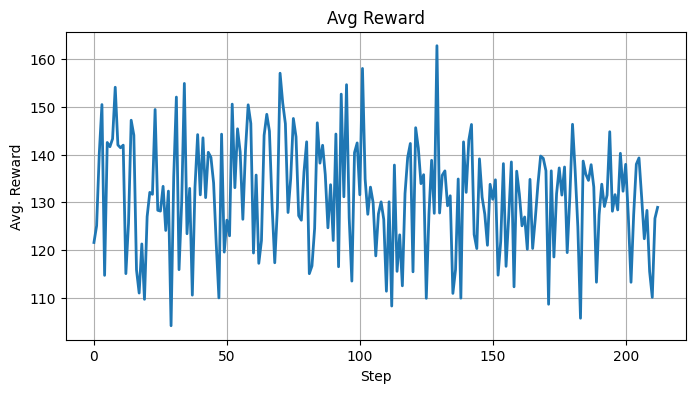

update policy in 0.37 s
dist_reward 0.5083 | block_goal_dist: 0.1575 | angle_reward: 0.1165 | episode_end_reward: 0.0000
dist_reward 0.9134 | block_goal_dist: 0.1575 | angle_reward: 0.1165 | episode_end_reward: 0.0000
dist_reward 0.8967 | block_goal_dist: 0.1575 | angle_reward: 0.1165 | episode_end_reward: 0.0000


KeyboardInterrupt: 

In [ ]:
# model.load("ppo_mlp_histlen8.pt")
model.run(ax=ax)
plt.close(fig)  # Prevents a duplicate static image at the end

In [ ]:
model = PPO(env,
            policy_type='mlp',
            state_dim=hp.state_dim,
            action_dim=hp.action_dim,
            lr_actor=hp.lr_actor,
            lr_critic=hp.lr_critic,
            max_ppo_steps=hp.max_ppo_steps,
            max_episode_len=hp.max_episode_len,
            clip=hp.clip,
            discount_gamma=hp.discount_gamma,
            gae_lambda=hp.gae_lambda,
            update_epochs=hp.update_epochs,
            batch_size=hp.batch_size,
            entropy_coefficient=hp.entropy_coefficient
        )

NameError: name 'ActorCriticCNN' is not defined

In [ ]:
model.run()

dist_reward 0.13029848488038462 | base_reward: 0.08172707848595837 | progress_reward: -0.7507124961073819 | angle_progress_reward: 1.488923249643371e-08
dist_reward 0.11889533305595985 | base_reward: 0.08172707848595837 | progress_reward: 0.0 | angle_progress_reward: 0.0
dist_reward 0.11711926701648619 | base_reward: 0.08172707848595837 | progress_reward: 0.0 | angle_progress_reward: 0.0
Step 000/500 | Avg Reward: 24.4972 | Avg Episode Length: 300.0 | collect time: 6.92 s
update policy in 0.37 s
dist_reward 0.13433774352074748 | base_reward: 0.03777328643723373 | progress_reward: -1.0 | angle_progress_reward: -1.9092256824598876e-07
dist_reward 0.1277713018415017 | base_reward: 0.03777328643723373 | progress_reward: 0.0 | angle_progress_reward: 0.0
dist_reward 0.12092045891112391 | base_reward: 0.03777328643723373 | progress_reward: 0.0 | angle_progress_reward: 0.0
Step 001/500 | Avg Reward: 18.1088 | Avg Episode Length: 300.0 | collect time: 7.18 s
update policy in 0.21 s
dist_reward 

KeyboardInterrupt: 

In [ ]:
model.save("ppo_mlp_histlen8.pt")

In [ ]:
def save_frames_as_gif(frames, path, fps=10, frame_stride=1, max_size=(512, 512)):
    from PIL import Image

    if not frames:
        raise ValueError("Cannot save a GIF with no frames")
    if fps <= 0:
        raise ValueError("fps must be positive")
    if frame_stride < 1:
        raise ValueError("frame_stride must be at least 1")

    images = []
    for frame in frames[::frame_stride]:
        frame = np.asarray(frame)
        if frame.ndim != 3 or frame.shape[2] < 3:
            raise ValueError(f"Expected an RGB image, got shape {frame.shape}")
        if frame.dtype != np.uint8:
            frame = np.clip(frame, 0, 255).astype(np.uint8)

        image = Image.fromarray(np.ascontiguousarray(frame[:, :, :3]), mode="RGB")
        if max_size is not None:
            image.thumbnail(max_size, Image.Resampling.BILINEAR)
        images.append(image)

    # GIF timing is quantized to 10 ms; preserve elapsed time when frames are skipped.
    duration = max(10, round((1000 * frame_stride / fps) / 10) * 10)
    images[0].save(
        path,
        save_all=True,
        append_images=images[1:],
        duration=duration,
        loop=0,
        optimize=False,
    )

## TODO: Need to enforce direction consistency and/or pick action every x timesteps

In [ ]:
### Test policy and save results as gifs

# asdf = model.save('checkpoint.pt')

# record 10 random rollouts
NUM_TEST_ROLLOUTS = 5
for i in range(NUM_TEST_ROLLOUTS):

    observation, info = env.reset()
    frames = []
    episode_steps = 0
    start_time = time.perf_counter()

    while episode_steps < model.MAX_EPISODE_LEN:
        state = torch.as_tensor(observation, dtype=torch.float32).unsqueeze(0)
        # action = model.policy.act(state)
        with torch.inference_mode():
            action, _, _ = model.policy_old.act(state)
            environment_action = model._to_environment_action(action)

        steps_to_run = min(
            model.action_every_n_steps,
            model.MAX_EPISODE_LEN - episode_steps,
        )
        for _ in range(steps_to_run):
            observation, reward, terminated, truncated, info = env.step(environment_action)
            episode_steps += 1
            frames.append(env.render())
            if terminated or truncated:
                break
        if terminated or truncated:
            break
    end_time = time.perf_counter()
    print(f'episode time elapsed: {(end_time-start_time):.3f}')

    save_frames_as_gif(frames, f'rolloutG_{i}.gif', fps=10, frame_stride=2, max_size=(256, 256))
    end_time2 = time.perf_counter()
    print(f'gif same time elapsed: {(end_time2 - end_time):.3f}')

episode time elapsed: 1.664


/tmp/ipykernel_1101/1720998560.py:19: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(np.ascontiguousarray(frame[:, :, :3]), mode="RGB")


gif same time elapsed: 2.030
episode time elapsed: 1.669
gif same time elapsed: 2.910
episode time elapsed: 1.648
gif same time elapsed: 2.116
episode time elapsed: 1.655
gif same time elapsed: 2.072
episode time elapsed: 1.584
gif same time elapsed: 2.844


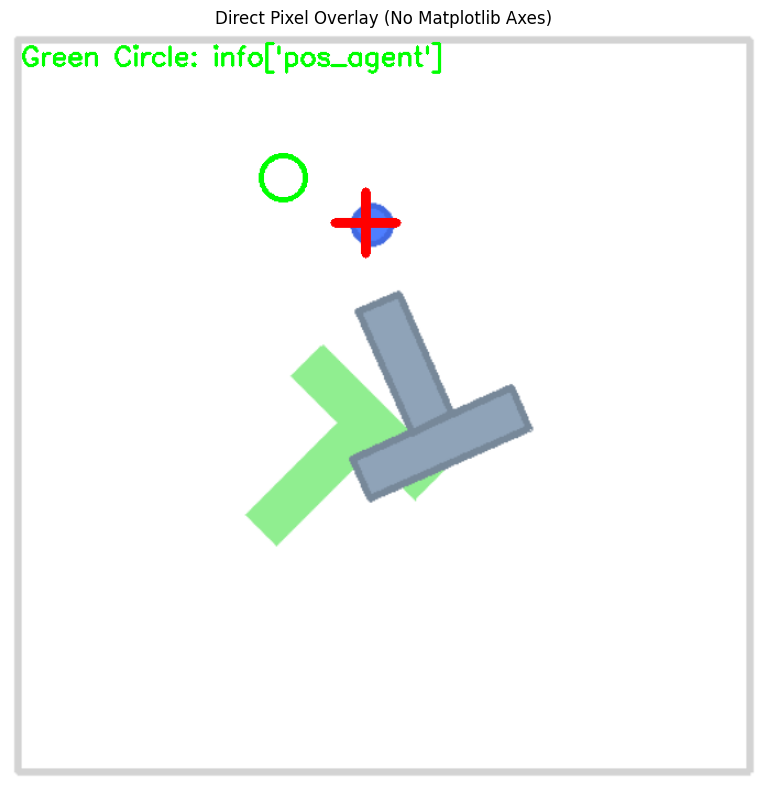

In [ ]:
import cv2

def test_pusher_position(env):
    # reset env
    obs, info = env.reset()

    actual_positions = []
    frames = []

    # Take 50 steps moving in a curve to observe the position drift
    for i in range(50):
        # Command a velocity action
        action = np.array([np.cos(i / 5.0), np.sin(i / 5.0)])
        obs, reward, terminated, truncated, info = env.step(action)

        actual_positions.append(info['pos_agent'].copy())
        frames.append(env.render())

    actual_positions = np.array(actual_positions)

    # Copy the final frame to modify it
    final_frame = np.ascontiguousarray(frames[-1].copy())

    # Draw a green circle directly onto the image pixels at the exact raw coordinates
    final_pos = actual_positions[-1]
    center_x, center_y = int(final_pos[0]), int(final_pos[1])

    # Green circle, thickness 3
    cv2.circle(final_frame, (center_x, center_y), radius=20, color=(0, 255, 0), thickness=3)
    cv2.putText(final_frame, "Green Circle: info['pos_agent']", (10, 30),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(final_frame)
    ax.set_title('Direct Pixel Overlay (No Matplotlib Axes)')
    ax.axis('off')

    plt.tight_layout()
    display(fig)
    plt.close(fig)

# Run the test
test_pusher_position(env)


In [ ]:
import cv2
import numpy as np

def find_pusher_center(img):
    # Convert RGB to HSV to easily isolate the blue/teal pusher
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    # Range for blue/cyan colors in HSV
    lower_blue = np.array([80, 50, 50])
    upper_blue = np.array([130, 255, 255])
    mask = cv2.inRange(hsv, lower_blue, upper_blue)

    # Find contours
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return None

    # Assume the largest blue contour is the pusher
    c = max(contours, key=cv2.contourArea)
    M = cv2.moments(c)
    if M["m00"] == 0:
        return None

    cx = M["m10"] / M["m00"]
    cy = M["m01"] / M["m00"]
    return (cx, cy)

print("--- Coordinate Mapping Analysis ---")
obs, info = env.reset()

agent_positions = []
detected_centers = []

# Take a few random steps to collect data points
for i in range(20):
    action = env.action_space.sample()
    obs, reward, terminated, truncated, info = env.step(action)
    img = env.render()

    center = find_pusher_center(img)
    if center is not None:
        agent_positions.append(info['pos_agent'].copy())
        detected_centers.append(center)

agent_positions = np.array(agent_positions)
detected_centers = np.array(detected_centers)

if len(detected_centers) > 0:
    print(f"Sample info['pos_agent']: {agent_positions[0]}")
    print(f"Sample Rendered Pixel:   {detected_centers[0]}")

    # Calculate the scale (Rendered Pixel / Physics Coordinate)
    scale_x = detected_centers[:, 0] / agent_positions[:, 0]
    scale_y = detected_centers[:, 1] / agent_positions[:, 1]

    print("\nCalculated Scales:")
    print(f"Scale X: {np.mean(scale_x):.4f} (std: {np.std(scale_x):.4f})")
    print(f"Scale Y: {np.mean(scale_y):.4f} (std: {np.std(scale_y):.4f})")

    # Calculate offset if any (Y = mX + b)
    offset_x = detected_centers[:, 0] - (agent_positions[:, 0] * np.mean(scale_x))
    offset_y = detected_centers[:, 1] - (agent_positions[:, 1] * np.mean(scale_y))
    print(f"\nCalculated Offsets:")
    print(f"Offset X: {np.mean(offset_x):.4f}")
    print(f"Offset Y: {np.mean(offset_y):.4f}")
else:
    print("Could not detect the pusher in the images.")

--- Coordinate Mapping Analysis ---
Sample info['pos_agent']: [241.0677  161.21222]
Sample Rendered Pixel:   [214.72755615 240.51160994]

Calculated Scales:
Scale X: 0.8726 (std: 0.0102)
Scale Y: 1.5282 (std: 0.0395)

Calculated Offsets:
Offset X: -0.0160
Offset Y: -0.1713


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# The expected base environment state format is: [agent_x, agent_y, block_x, block_y, block_angle]
# Let's pick a distinct, safe state to verify it works.
test_state = [150.0, 150.0, 300.0, 300.0, 0.5]

print("--- Testing reset_to_state ---")
options = {"reset_to_state": test_state}
obs, info = env.reset(options=options)

print(f"Requested State: Agent(150, 150), Block(300, 300), Angle(0.5)")
print(f"Actual Agent Pos: {info['pos_agent']}")
print(f"Actual Block Pos: {info['block_pose'][:2]}")
print(f"Actual Block Ang: {info['block_pose'][2]:.4f}")

print("\n--- Testing Physics Stability ---")
print("Taking a zero-action step to check for snap-backs...")
# PushTVelocityWrapper takes [-1, 1] normalized velocity, [0, 0] means stop
action = np.array([0.0, 0.0], dtype=np.float32)
next_obs, reward, term, trunc, next_info = env.step(action)

print(f"Agent Pos after step: {next_info['pos_agent']}")
print(f"Block Pos after step: {next_info['block_pose'][:2]}")

# Render to verify visually
img = env.render()
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.title("Render after reset_to_state & 1 step")
plt.axis("off")
plt.show()

--- Testing reset_to_state ---
Requested State: Agent(150, 150), Block(300, 300), Angle(0.5)
Actual Agent Pos: [150. 150.]
Actual Block Pos: [321.57416 305.5088 ]
Actual Block Ang: 0.5000

--- Testing Physics Stability ---
Taking a zero-action step to check for snap-backs...
Agent Pos after step: [150. 150.]
Block Pos after step: [321.57414924 305.50878471]
